In [10]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [16]:
class BatsmanState(TypedDict):
    runs : int
    balls : int
    fours : int
    sixes : int

    strike_rate : float
    balls_per_boundary : float
    boundary_percent : float
    summary : str

In [25]:
def calculate_strike_rate(state : BatsmanState):

    strike_rate = (state['runs'] / state['balls']) * 100

    return {'strike_rate' : strike_rate}

In [18]:
def calculate_balls_per_boundary(state : BatsmanState):

    balls_per_boundary = state['balls'] / (state['fours'] + state['sixes'])

    return { 'balls_per_boundary' : balls_per_boundary}

In [34]:
def calculate_boundary_percent(state : BatsmanState):

    boundary_percent = (((state['fours'] * 4) + (state['sixes'] * 6)) * 100) / 100
    
    return {'boundary_percent' : boundary_percent }

In [37]:
def summary(state : BatsmanState):
    summary = f"""
Strike Rate - {state['strike_rate']} Runs per 100 balls \n
Balls per boundary - {state['balls_per_boundary']} Balls \n
Boundary percent - {state['boundary_percent']}%
"""
    return {'summary' : summary}

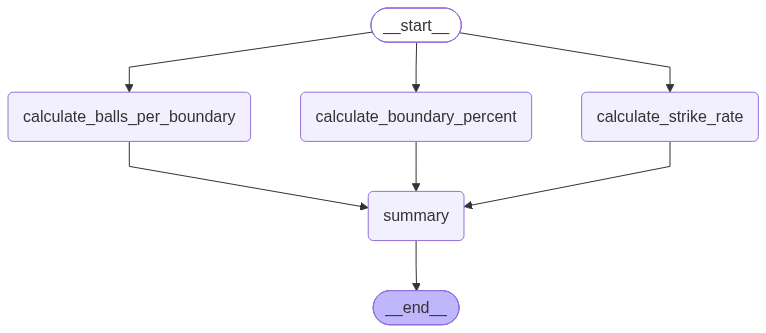

In [38]:
graph = StateGraph(BatsmanState)

graph.add_node('calculate_strike_rate', calculate_strike_rate)
graph.add_node('calculate_balls_per_boundary', calculate_balls_per_boundary)
graph.add_node('calculate_boundary_percent', calculate_boundary_percent)
graph.add_node('summary', summary)


graph.add_edge(START, 'calculate_strike_rate')
graph.add_edge(START, 'calculate_balls_per_boundary')
graph.add_edge(START, 'calculate_boundary_percent')

graph.add_edge('calculate_strike_rate', 'summary')
graph.add_edge('calculate_balls_per_boundary', 'summary')
graph.add_edge('calculate_boundary_percent', 'summary')

graph.add_edge('summary', END)

workflow = graph.compile()
workflow

In [39]:
initial_state = {
    'runs' : 100,
    'balls' : 50,
    'fours' : 6,
    'sixes' : 4,
}
final_state = workflow.invoke(initial_state)
final_state

{'runs': 100,
 'balls': 50,
 'fours': 6,
 'sixes': 4,
 'strike_rate': 200.0,
 'balls_per_boundary': 5.0,
 'boundary_percent': 48.0,
 'summary': '\nStrike Rate - 200.0 Runs per 100 balls \n\nBalls per boundary - 5.0 Balls \n\nBoundary percent - 48.0%\n'}

In [40]:
print(final_state['summary'])


Strike Rate - 200.0 Runs per 100 balls 

Balls per boundary - 5.0 Balls 

Boundary percent - 48.0%

